# Cardio dataset: Exploratory Data Analysis

The test set will remain unseen when making EDA decisions for processing, to avoid data leakage from outliers, thresholds, patterns which may leak from it.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from data import TARGET, split_data

sns.set_theme(style="whitegrid")
CLASS_COLOURS = ["#2871cb", "#dd6232"]

train_df, _ = split_data()
print(train_df.shape)
train_df.head()

(56000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
58394,83327,18995,2,162,83.0,120.0,80.0,1,1,0,0,0,1
60371,86196,17319,1,158,64.0,120.0,80.0,1,1,0,0,1,0
41399,59158,19017,1,165,95.0,160.0,100.0,2,1,0,0,1,1
11468,16399,20388,1,164,83.0,150.0,100.0,1,1,0,0,1,1
20650,29470,18236,1,156,52.0,100.0,67.0,1,1,0,0,0,0


## 1. Target balance
Is `cardio` balanced? This decides whether we need class weights / SMOTE later.

        count   share
cardio               
0       28017  0.5003
1       27983  0.4997


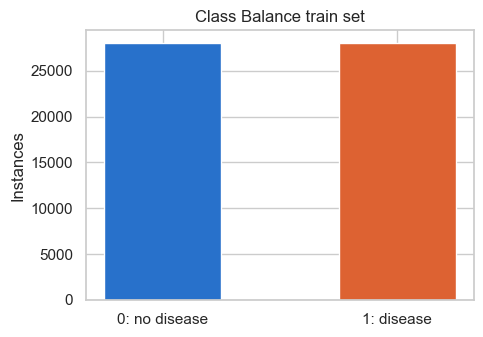

In [2]:
counts = train_df[TARGET].value_counts().sort_index()
print(pd.DataFrame({"count": counts, "share": counts / counts.sum()}).round(4))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["0: no disease", "1: disease"], counts.values, color=CLASS_COLOURS, width=0.5)

ax.set_title("Class Balance train set")
ax.set_ylabel("Instances")
plt.show()

## 2. Summary statistics
Use `describe()` to give min / max / mean per column. Impossible mins and maxes are a sign of entry errors or outliers

In [3]:
pd.set_option("display.float_format", "{:.2f}".format)
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,56000.00,49997.02,28874.26,0.00,24993.75,50001.50,74949.50,99999.00
age,56000.00,19466.63,2461.79,10859.00,17669.50,19698.00,21321.00,23692.00
gender,56000.00,1.35,0.48,1.00,1.00,1.00,2.00,2.00
height,56000.00,164.34,8.23,57.00,159.00,165.00,170.00,250.00
weight,56000.00,74.22,14.39,11.00,65.00,72.00,82.00,200.00
ap_hi,56000.00,129.04,161.55,-150.00,120.00,120.00,140.00,16020.00
ap_lo,56000.00,96.80,193.57,-70.00,80.00,80.00,90.00,11000.00
cholesterol,56000.00,1.37,0.68,1.00,1.00,1.00,2.00,3.00
gluc,56000.00,1.23,0.57,1.00,1.00,1.00,1.00,3.00
smoke,56000.00,0.09,0.28,0.00,0.00,0.00,0.00,1.00


We count the unique values per column to help separate continuous columns from categorical ones

In [4]:
train_df.nunique().sort_values()

gender             2
active             2
alco               2
smoke              2
cardio             2
cholesterol        3
gluc               3
height           105
ap_lo            145
ap_hi            147
weight           263
age             7911
id             56000
dtype: int64

In [5]:
print("Duplicate rows:", train_df.drop(columns="id").duplicated().sum())
print("Missing values:", train_df.isna().sum().sum())

Duplicate rows: 17
Missing values: 0


## 3. Normal distribution (height and weight)
If height and weight follow a normal distribution, we can find the **p < 0.05** instances which lie outside the middle 95% of the normal distribution

Typically 68% of values are within 1 std of the mean, 95% within 2 std, and 99.7% within 3 std. We can use a **z-score** to measure how many standard deviations a value is from the mean
`z = (value - mean) / std`

The two-tailed **p-value** is the share of the normal curve at least as far from the mean as that value, in either tail. A small p means the value is rare

In [6]:
from scipy.stats import norm

ALPHA = 0.05


def normal_95_range(series, alpha=ALPHA):
    """Fit a normal distribution to a column and return its p-values and 95% limits."""
    z = (series - series.mean()) / series.std()
    p = 2 * (1 - norm.cdf(z.abs()))
    z_crit = norm.ppf(1 - alpha / 2)
    return p, series.mean() - z_crit * series.std(), series.mean() + z_crit * series.std()


summary = []
for col in ["height", "weight"]:
    p, low, high = normal_95_range(train_df[col])
    summary.append({
        "column": col,
        "normal 95% low": low,
        "normal 95% high": high,
        "actual 2.5% quantile": train_df[col].quantile(0.025),
        "actual 97.5% quantile": train_df[col].quantile(0.975),
        "rows with p < 0.05": (p < ALPHA).sum(),
        "skew": train_df[col].skew(),
    })
pd.DataFrame(summary).set_index("column").T

column,height,weight
normal 95% low,148.22,46.02
normal 95% high,180.47,102.43
actual 2.5% quantile,150.00,51.00
actual 97.5% quantile,180.00,108.00
rows with p < 0.05,2111.00,2677.00
skew,-0.70,1.01


Height and weight by gender, to check which code is which

In [7]:
train_df.groupby("gender")[["height", "weight"]].mean()

,height,weight
gender,,
1,161.34,72.62
2,169.95,77.22


Weight has a long right tail, so the normal curve fits it badly. A p < 0.05 cut would remove heavy patients, and weight is a heart-disease risk factor, so that throws away useful signal. Height has a long left tail, so a cut would remove shorter patients.

It's better to cut at impossible thresholds instead. Heights like 57cm or 250cm are implausible for adults aged 30 to 65 and are almost certainly entry errors, so our height range shall be 130cm to 210cm, which covers essentially all adults. For weight I shall remove anything under 40kg, with no upper cap, because heavy patients (up to 200kg) are possible and are a high risk group

## 4. Numeric distributions and boxplots
Histograms show the shape of each column. Boxplots show the median, the middle 50% and the outliers

We also derive **BMI** which combines height and weight into one number: `weight / (height in metres)²`. A healthy adult BMI is roughly 18.5 to 25. This also allows us to assess the relation between a person's height and weight, as they are not independent features. BMI replaces a height vs weight scatter plot because it measures the same relationship as one number

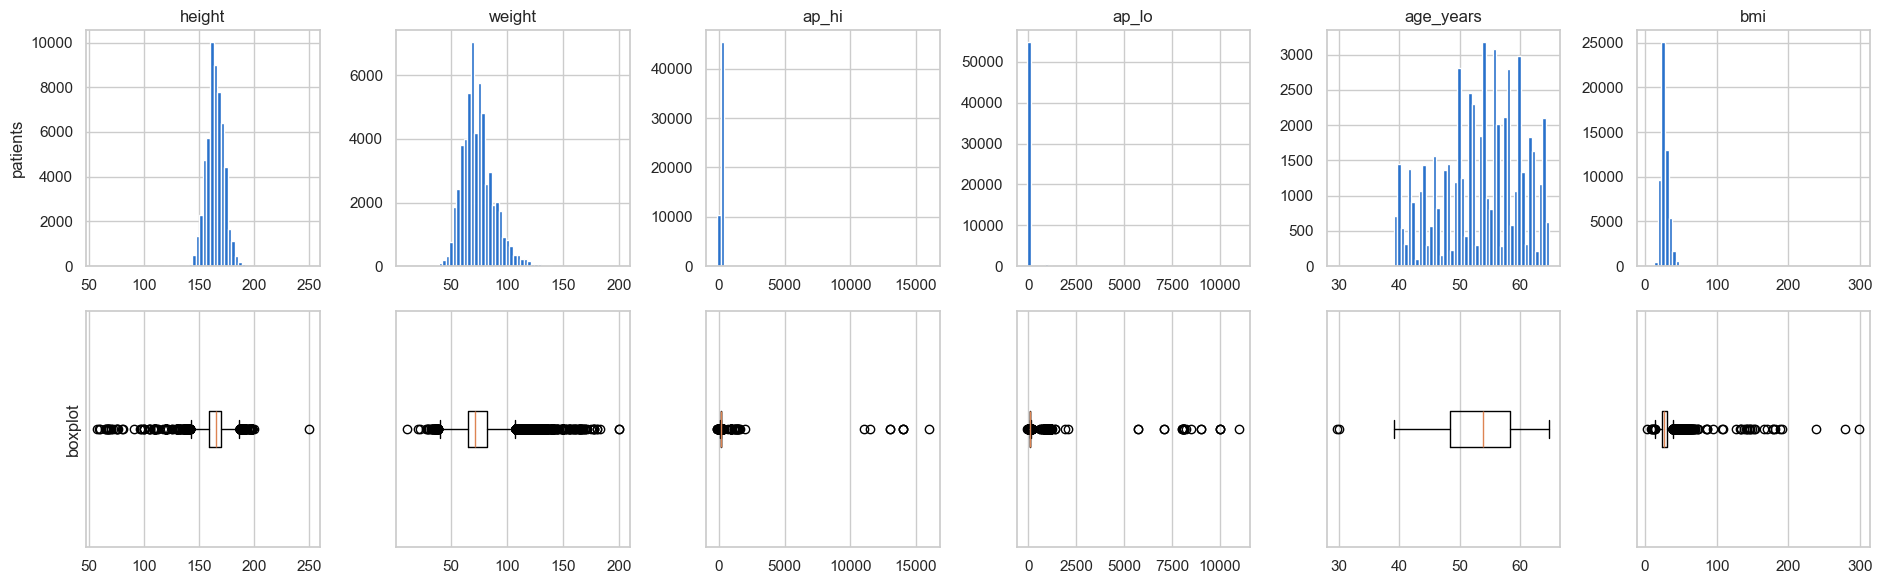

In [8]:
numeric = train_df[["height", "weight", "ap_hi", "ap_lo"]].assign(
    age_years=train_df["age"] / 365.25,
    bmi=train_df["weight"] / (train_df["height"] / 100) ** 2,
)

fig, axes = plt.subplots(2, 6, figsize=(19, 6))
for i, col in enumerate(numeric.columns):
    axes[0, i].hist(numeric[col], bins=60, color=CLASS_COLOURS[0])
    axes[0, i].set_title(col)
    axes[1, i].boxplot(numeric[col], vert=False)
    axes[1, i].set_yticks([])
axes[0, 0].set_ylabel("patients")
axes[1, 0].set_ylabel("boxplot")
plt.tight_layout()
plt.show()

In [9]:
bmi_checks = {
    "BMI std": numeric["bmi"].std(),
    "BMI mean": numeric["bmi"].mean(),
    "BMI < 12": (numeric["bmi"] < 12).sum(),
    "BMI < 12 (Other Restrictions)": (
    (numeric["bmi"] < 12) & 
    (130 <= numeric["height"]) & 
    (numeric["height"] <= 210) & 
    (40 <= numeric["weight"])
    ).sum(),
    "BMI > 80": (numeric["bmi"] > 80).sum(),
    "BMI > 80 (Other Restrictions)": (
        (numeric["bmi"] > 80) & 
        (130 <= numeric["height"]) & 
        (numeric["height"] <= 210) & 
        (40 <= numeric["weight"])
        ).sum(),
    "skew": numeric["bmi"].skew(),
}
pd.Series(bmi_checks, name="BMI")

BMI std                          6.17
BMI mean                        27.57
BMI < 12                         5.00
BMI < 12 (Other Restrictions)    0.00
BMI > 80                        30.00
BMI > 80 (Other Restrictions)    1.00
skew                             7.85
Name: BMI, dtype: float64

• Lower Bound: BMI < 12 (A BMI below 12 is generally incompatible with human life)  
• Upper Bound: BMI > 80 (Values above 80 are exceptionally rare outliers)  

Most of them come from the height and weight errors. After applying the 130cm to 210cm height rule and the 40kg weight rule, all 5 BMIs under 12 are removed and only 1 BMI over 80 remains (85.8)

### Blood pressure errors
A normal reading is roughly 90 to 140 for ap_hi and 60 to 90 for ap_lo.  
A human systolic blood pressure cannot drop below 0 or exceed roughly 370 mmHg

In [10]:
bp_checks = {
    "ap_hi <= 0": (train_df["ap_hi"] <= 0).sum(),
    "ap_lo <= 0": (train_df["ap_lo"] <= 0).sum(),
    "ap_hi > 250": (train_df["ap_hi"] > 250).sum(),
    "ap_lo > 200": (train_df["ap_lo"] > 200).sum(),
    "ap_hi < 50 (and > 0)": ((train_df["ap_hi"] > 0) & (train_df["ap_hi"] < 50)).sum(),
    "ap_lo < 30 (and > 0)": ((train_df["ap_lo"] > 0) & (train_df["ap_lo"] < 30)).sum(),
}
pd.Series(bp_checks, name="rows")

ap_hi <= 0                5
ap_lo <= 0               18
ap_hi > 250              37
ap_lo > 200             760
ap_hi < 50 (and > 0)    145
ap_lo < 30 (and > 0)     24
Name: rows, dtype: int64

## 5. Scatter plots
A scatter plot puts one column on each axis, so every dot is one patient. It finds errors that look fine when each column is checked on its own

### ap_hi vs ap_lo
ap_hi (systolic) should always be higher than ap_lo (diastolic). Dots **above** the dashed line have ap_lo > ap_hi, which is impossible

The axes are limited to 0 to 250 and 0 to 200, otherwise the extreme errors squash every other dot into one corner

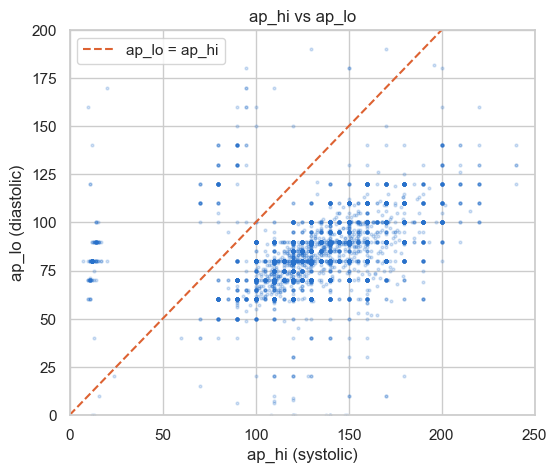

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(train_df["ap_hi"], train_df["ap_lo"], s=4, alpha=0.2, color=CLASS_COLOURS[0])
ax.plot([0, 250], [0, 250], color=CLASS_COLOURS[1], linestyle="--", label="ap_lo = ap_hi")
ax.set_xlim(0, 250)
ax.set_ylim(0, 200)
ax.set_xlabel("ap_hi (systolic)")
ax.set_ylabel("ap_lo (diastolic)")
ax.set_title("ap_hi vs ap_lo")
ax.legend()
plt.show()

In [12]:
print("Rows with ap_lo > ap_hi:", (train_df["ap_lo"] > train_df["ap_hi"]).sum())
print("Rows with ap_lo == ap_hi:", (train_df["ap_lo"] == train_df["ap_hi"]).sum())

Rows with ap_lo > ap_hi: 982
Rows with ap_lo == ap_hi: 2


## 6. Categorical columns
For each category we look at two things:
- **count**: how many patients are in it
- **cardio rate**: the share of those patients with heart disease

If the cardio rate changes a lot between categories, the column is likely to be a useful

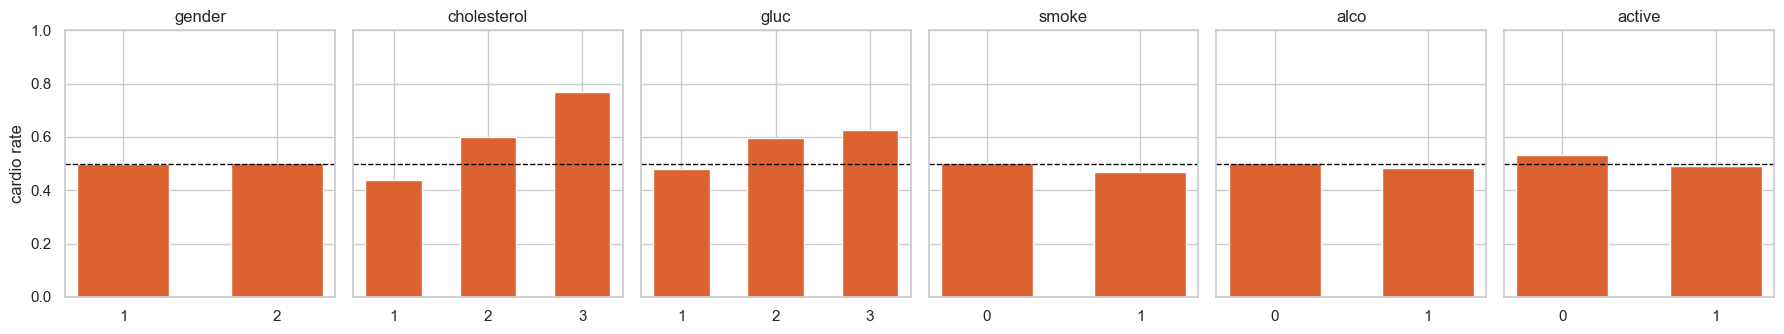

In [81]:
categorical = ["gender", "cholesterol", "gluc", "smoke", "alco", "active"]

fig, axes = plt.subplots(1, 6, figsize=(18, 3.5), sharey=True)
for ax, col in zip(axes, categorical):
    rate = train_df.groupby(col)[TARGET].mean()
    ax.bar(rate.index.astype(str), rate.values, color=CLASS_COLOURS[1], width=0.6)
    ax.axhline(train_df[TARGET].mean(), color="black", linestyle="--", linewidth=1)
    ax.set_title(col)
    ax.set_ylim(0, 1)
axes[0].set_ylabel("cardio rate")
plt.tight_layout()
plt.show()

### Findings so far
- Classes are balanced: 28,017 no-disease vs 27,983 disease (50.0% / 50.0%). Class weights or SMOTE not needed.
- No missing values
- 17 duplicate rows, which should be removed to prevent heavier weightings towards these instances
- Age is in days and needs to be converted to years. The youngest patient is 29.7 years old, so no under-18 filter is needed
- Height runs from 57 to 250 cm. Both ends are implausible for adults, so we keep 130cm to 210cm
- Weight runs from 11 to 200 kg. 11 kg is impossible for an adult, so we remove anything under 40kg and keep heavy patients
- ap_hi runs from -150 to 16,020 and ap_lo from -70 to 11,000. Negative and extremely high values are entry errors, but the quartiles (120 to 140 and 80 to 90) are normal, so only a small number of rows are affected 
- Binary columns (smoke, alco, active, cardio) only contain 0 and 1, and cholesterol and gluc only contain 1 to 3, so there are no invalid category codes
- Gender is coded 1/2. Gender 2 is on average about 9cm taller and 5kg heavier, so 2 is most likely male, although the dataset doesn't document it
- BMI runs from 3.5 to 298.7 with a skew of 7.85. We treat BMI < 12 and BMI > 80 as implausible, and after the height and weight rules only 1 row is still above 80
- 982 rows have ap_lo > ap_hi, which is impossible, and 2 have ap_lo == ap_hi. Most are the extreme ap_lo errors, so these rows should be removed